# Fáza 4 - Deep Learning

Hugo Foltin, Teodor Potančok

## Výber datasetu

Vybrali sme si Quest 1 (klasifikácia). Dataset ktorý na to používame je [Ecommerce classify the objects based on their text description](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification). Cieľ je vytrénovať NLP model ktorý vie čo najlepšie rozdeliť produkty do 4 kategórii podľa ich popisu.

## 4.1A EDA a data preprocessing

Pre začiatok načítame dataset z CSV a zistíme základné štatistiky.

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data = pd.read_csv("data/ecommerceDataset.csv", header=0, names=["label", "text"])

data.describe()

,label,text
count,50424,50423
unique,4,27801
top,Household,Think & Grow Rich About the Author NAPOLEON HI...
freq,19312,30


Vidíme že dataset má skutočne 4 kategórie (rôzne hodnoty `label`). V atribúte `text` máme 27 000 duplikátov, čo vychádza na 55.1% zo všetkých záznamov. Najčastejšia hodnota `Think & Grow Rich...` sa opakuje 30 krát.

In [31]:
data["label"].unique()

<StringArray>
['Household', 'Books', 'Clothing & Accessories', 'Electronics']
Length: 4, dtype: str

In [32]:
top_texts = data["text"].value_counts().head(30)
top_texts

text
Think & Grow Rich About the Author NAPOLEON HILL, born in Pound, Southwest Virginia in 1883, was a very successful American author in the area of the new thought movement—one of the earliest producers of the modern genre of personal-success literature. He is widely considered to be one of the great writers on success. The turning point in Hill’s life occurred in the year 1908 when he interviewed the industrialist Andrew Carnegie—one of the most powerful men in the world at that time, as part of an assignment—an interview which ultimately led to the publication of Think and Grow Rich, one of his best-selling books of all time. the book examines the power of personal beliefs and the role they play in personal success. Hill, who had even served as the advisor to President Franklin D. Roosevelt from 1933-36, passed away at the age of 87.                                                                                                                                                      

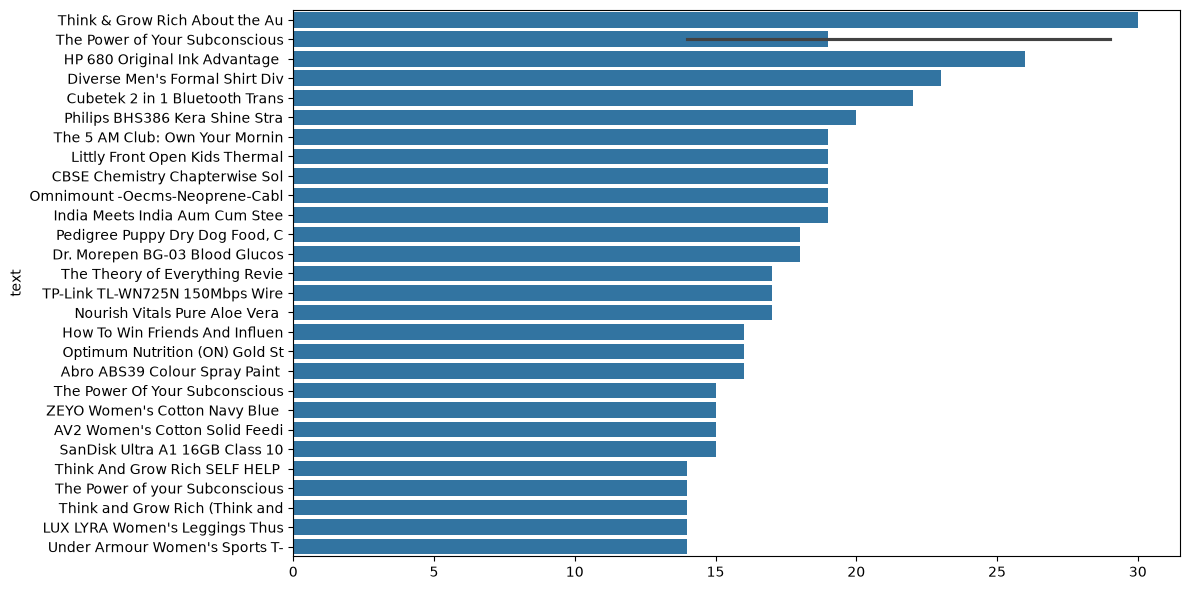

In [33]:
display_labels = top_texts.index.str.slice(0, 30)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_texts.values, y=display_labels)
plt.tight_layout()
plt.show()

Vyzerá že hlavný preprocessing ktorý potrebujeme je odstrániť duplikáty, aby sme predišli overfittingu alebo nekonzistentným zaradeniam (v prípade že niektorý produkt má v každom riadku inú kategóriu).

In [34]:
data = data.drop_duplicates(subset="text").reset_index(drop=True)

Okrem toho je dobré previesť všetko na malé písmená a odstrániť znaky ako `():'",.`, ktoré robia problémy pri tokenizácii - `(Black,` a `black` by sme mali brať ako rovnaký token.

In [ ]:
data["text"] = data["text"].str.lower().str.replace(r"[^a-zA-Z0-9\s]", " ", regex=True).str.strip()

data.head(10)

,label,text
0,Household,saf floral framed painting wood 30 inch x ...
1,Household,saf uv textured modern art print framed pain...
2,Household,saf flower print framed painting synthetic 1...
3,Household,incredible gifts india wooden happy birthday u...
4,Household,pitaara box romantic venice canvas painting 6m...


## 4.2B Výber ML metód

- RNN
- TF-IDF + SGD Classifier
- TF-IDF + Naive Bayes